# Trabajo Práctico 2: Regularización y árboles
PE1333 Big Data, Maestría en Economía - UdeSA 2026. Grupo 9.

## Parte I: Regresión logística con regularización, Ridge y LASSO

### Preparación (común a los incisos 1 y 2)
#### 0.1 Librerías, semilla y versiones
Cargamos las librerías y fijamos la semilla (444, la misma del TP1). Imprimimos las versiones porque
`LogisticRegression` cambió su interfaz en scikit-learn 1.8: el argumento `penalty` quedó obsoleto y la
penalidad se elige con `l1_ratio` (1 = LASSO, 0 = Ridge). La función `kw_penalidad` devuelve los
argumentos correctos según la versión instalada, para que el notebook corra igual en cualquier
computadora del grupo. La función `es_cero` cuenta los coeficientes nulos con `np.isclose(..., atol=1e-8)`,
como en la Tutorial 5 (`Tut5_Regularizacion.ipynb`, sección "Cantidad de coeficientes que LASSO lleva a 0").

In [1]:
import os
import time
import warnings
import inspect

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.model_selection import KFold
from sklearn.exceptions import ConvergenceWarning

SEMILLA = 444
os.makedirs("figuras", exist_ok=True)   # crea TP2/figuras si no existe
os.makedirs("tablas", exist_ok=True)    # crea TP2/tablas si no existe

print("Python", os.sys.version.split()[0], "| scikit-learn", sklearn.__version__,
      "| pandas", pd.__version__, "| numpy", np.__version__,
      "| matplotlib", matplotlib.__version__, "| seaborn", sns.__version__)

# True si scikit-learn es 1.8 o posterior (interfaz nueva: l1_ratio en lugar de penalty)
def es_cero(b):
    # Igual que en la Tutorial 5: un coeficiente cuenta como cero si su valor absoluto es menor o igual a 1e-8
    return np.isclose(b, 0, atol=1e-8)

SK_NUEVO = tuple(int(p) for p in sklearn.__version__.split(".")[:2]) >= (1, 8)

def kw_penalidad(tipo, cv=False):
    # Argumentos que eligen la penalidad. tipo: "l1" (LASSO) o "l2" (Ridge).
    # cv=True: argumentos para LogisticRegressionCV, que recibe una lista de l1_ratios.
    mezcla = 1.0 if tipo == "l1" else 0.0
    if not SK_NUEVO:
        return {"penalty": tipo}
    return {"l1_ratios": (mezcla,)} if cv else {"l1_ratio": mezcla}

Python 3.14.6 | scikit-learn 1.9.0 | pandas 3.0.3 | numpy 2.4.6 | matplotlib 3.11.0 | seaborn 0.13.2


#### 0.2 Base de datos y partición
No agregamos variables respecto del TP1, así que la base es la misma: la leemos directamente de
`../TP1/data/base_limpia_TP1.csv` (ruta relativa a `TP2`) en lugar de duplicarla en `TP2/data`.
La partición 70/30 con `random_state = 444` se reproduce con la columna `muestra`, que guardó el TP1.
La celda verifica las dimensiones (19.482 ocupados, 67 predictoras, 13.637 de entrenamiento y 5.845 de
test) y se detiene si alguna no coincide. La base de test no se usa en los incisos 1 y 2.

In [2]:
base = pd.read_csv("../TP1/data/base_limpia_TP1.csv")

no_x = ["CODUSU", "NRO_HOGAR", "COMPONENTE", "muestra", "informal"]
x_cols = [c for c in base.columns if c not in no_x]

train = base[base["muestra"] == "train"]
X_train = train[x_cols].astype(float)     # sin columna de unos
y_train = train["informal"]

print("Base:", base.shape, "| predictoras:", len(x_cols), "| NaN:", int(base.isna().sum().sum()))
print("Partición:", base["muestra"].value_counts().to_dict())
print(f"Informales en entrenamiento: {y_train.mean():.4f}")

assert base.shape[0] == 19482 and len(x_cols) == 67
assert (base["muestra"] == "train").sum() == 13637 and (base["muestra"] == "test").sum() == 5845
assert "const" not in x_cols

Base: (19482, 72) | predictoras: 67 | NaN: 0
Partición: {'train': 13637, 'test': 5845}
Informales en entrenamiento: 0.4473


#### 0.3 Estandarización con medias y desvíos del entrenamiento
La penalidad suma los coeficientes (en valor absoluto o al cuadrado), así que depende de la unidad de
medida de cada variable: por eso la consigna pide estandarizar. `StandardScaler().fit(X_train)` calcula
la media y el desvío de cada una de las 67 columnas **sólo con la base de entrenamiento**, y `transform`
resta esa media y divide por ese desvío (el mismo procedimiento de la Tutorial 5). Se estandarizan todas las columnas, incluidas las dummies, como
indica la consigna. `StandardScaler` usa el desvío poblacional (divide por $n$, no por $n-1$).

**Decisión sobre la columna de unos.** La consigna pide estimar sin la columna de unos del TP1. La
leemos así: la matriz X no lleva la columna `const` (que además no se podría estandarizar, porque su
desvío es cero), y el intercepto lo estima scikit-learn por su cuenta (`fit_intercept=True`, el valor
por defecto), sin penalizarlo, como en las slides de la Tutorial 5 ("El intercepto no se penaliza").
Sin ningún intercepto, con las X centradas en cero, el modelo quedaría
obligado a predecir probabilidad 0,5 para la persona promedio, cuando la proporción de informales en
entrenamiento es 0,447.

In [3]:
escalador = StandardScaler().fit(X_train)          # medias y desvíos del entrenamiento
X_train_std = pd.DataFrame(escalador.transform(X_train), columns=x_cols, index=X_train.index)

print("Desvío mínimo antes de estandarizar:", round(float(escalador.scale_.min()), 4),
      "(", x_cols[int(escalador.scale_.argmin())], ")")
print("Después de estandarizar -> máx |media|:", f"{X_train_std.mean().abs().max():.1e}",
      "| desvíos entre", round(float(X_train_std.std(ddof=0).min()), 6),
      "y", round(float(X_train_std.std(ddof=0).max()), 6))

Desvío mínimo antes de estandarizar: 0.0645 ( lugar_trabajo_chacra )
Después de estandarizar -> máx |media|: 3.7e-16 | desvíos entre 1.0 y 1.0


### Inciso 1
#### 1.1 Grilla de λ y su relación con `C`
La grilla es $\lambda = 10^n$ con $n \in \{-5, \dots, 5\}$ (11 valores). scikit-learn minimiza
$$C \sum_{i=1}^{n} \ell_i(\beta_0, \beta) + P(\beta), \qquad P(\beta)=\sum_j |\beta_j| \text{ (LASSO)}, \quad P(\beta)=\tfrac{1}{2}\sum_j \beta_j^2 \text{ (Ridge)}$$
donde $\ell_i$ es la pérdida logística (menos la log-verosimilitud) de la observación $i$. Dividir todo
por $C$ no cambia el mínimo y deja $\sum_i \ell_i + \frac{1}{C} P(\beta)$: por eso $\lambda = 1/C$, como
dicen el hint de la consigna y las slides de la Tutorial 5 ("C multiplica al ajuste, así que es la inversa
de la penalidad"). Dos detalles de esta convención: la pérdida es la **suma** sobre las 13.637
observaciones (no el promedio), y la penalidad Ridge lleva un factor $\tfrac12$.

In [4]:
exponentes = np.arange(-5, 6)             # n = -5, -4, ..., 5
lambdas = 10.0 ** exponentes              # λ = 10^n
Cs = 1.0 / lambdas                        # C = 1/λ
etiquetas_lambda = [f"$10^{{{n}}}$" for n in exponentes]

print(pd.DataFrame({"n": exponentes, "lambda": lambdas, "C": Cs}).to_string(index=False))

 n       lambda            C
-5      0.00001 100000.00000
-4      0.00010  10000.00000
-3      0.00100   1000.00000
-2      0.01000    100.00000
-1      0.10000     10.00000
 0      1.00000      1.00000
 1     10.00000      0.10000
 2    100.00000      0.01000
 3   1000.00000      0.00100
 4  10000.00000      0.00010
 5 100000.00000      0.00001


#### 1.2 Prueba de solvers
El *solver* es el algoritmo numérico que busca el mínimo. No todos admiten las dos penalidades:
LASSO sólo se puede estimar con `liblinear` o `saga`; Ridge admite además `lbfgs`, `newton-cg` y
`newton-cholesky`. Para cada combinación estimamos la grilla completa y registramos: el tiempo, el
máximo de iteraciones usadas (si es menor que `max_iter`, el algoritmo paró porque convergió y no porque
se le acabaron las iteraciones), la cantidad de avisos de no convergencia y el valor de la función
objetivo de 1.1 en $\lambda = 10^{-5}$ y en $\lambda = 10^{5}$ (más bajo = mejor mínimo). También
guardamos el intercepto en $\lambda = 10^{5}$, porque `liblinear` penaliza el intercepto y los demás no.

In [5]:
MAX_ITER = 10_000

def objetivo(modelo, C, tipo):
    # Función objetivo de 1.1 dividida por C: suma de pérdidas logísticas + λ · penalidad
    z = X_train_std.values @ modelo.coef_.ravel() + modelo.intercept_[0]
    perdida = np.sum(np.logaddexp(0, z) - y_train.values * z)
    b = modelo.coef_.ravel()
    penalidad = np.abs(b).sum() if tipo == "l1" else 0.5 * b @ b
    return perdida + penalidad / C

def estimar_grilla(tipo, solver):
    # Estima el logit penalizado para cada λ de la grilla. Devuelve modelos, tiempo y avisos.
    modelos, t0 = [], time.perf_counter()
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always", ConvergenceWarning)
        for C in Cs:
            m = LogisticRegression(C=C, solver=solver, max_iter=MAX_ITER, random_state=SEMILLA,
                                   **kw_penalidad(tipo))
            modelos.append(m.fit(X_train_std, y_train))
    n_avisos = sum(issubclass(a.category, ConvergenceWarning) for a in avisos)
    return modelos, time.perf_counter() - t0, n_avisos

candidatos = {"l1": ["liblinear", "saga"],
              "l2": ["lbfgs", "newton-cg", "newton-cholesky", "liblinear", "saga"]}
nombre_pen = {"l1": "LASSO", "l2": "Ridge"}

filas, pruebas = [], {}
for tipo, solvers in candidatos.items():
    for solver in solvers:
        modelos, segundos, n_avisos = estimar_grilla(tipo, solver)
        pruebas[(tipo, solver)] = modelos
        filas.append({"penalidad": nombre_pen[tipo], "solver": solver,
                      "segundos": round(segundos, 2),
                      "max_iteraciones": max(int(m.n_iter_.max()) for m in modelos),
                      "avisos_no_convergencia": n_avisos,
                      "objetivo_lambda_1e-5": objetivo(modelos[0], Cs[0], tipo),
                      "objetivo_lambda_1e5": objetivo(modelos[-1], Cs[-1], tipo),
                      "intercepto_lambda_1e5": modelos[-1].intercept_[0]})
prueba_solvers = pd.DataFrame(filas)
print(prueba_solvers.round(4).to_string(index=False))

penalidad          solver  segundos  max_iteraciones  avisos_no_convergencia  objetivo_lambda_1e-5  objetivo_lambda_1e5  intercepto_lambda_1e5
    LASSO       liblinear      2.99               21                       0             5007.4946            9452.4481                 0.0000
    LASSO            saga     12.49              265                       0             5007.4865            9376.6211                -0.2154
    Ridge           lbfgs      0.39               26                       0             5007.4937            9045.6736                -0.2128
    Ridge       newton-cg      0.89                7                       0             5007.4854            9045.6736                -0.2127
    Ridge newton-cholesky      0.48                5                       0             5007.4854            9045.6736                -0.2127
    Ridge       liblinear      1.06                6                       0             5007.4854            9117.0536                -0.0069

**Solver elegido** (los tiempos cambian de una computadora a otra; el resto de la tabla no):
- **LASSO: `saga`, con `max_iter = 10.000`.** Los dos candidatos convergen sin avisos. Elegimos `saga`
  porque no penaliza el intercepto, que es lo que corresponde a la consigna (se regularizan los
  coeficientes de las variables): con $\lambda = 10^5$ `liblinear` lleva el intercepto a cero junto con
  los coeficientes, y por eso su objetivo queda más alto. `saga` tarda más, pero sigue siendo cuestión
  de segundos.
- **Ridge: `newton-cholesky`, con `max_iter = 10.000`.** Converge en muy pocas iteraciones, es de los más
  rápidos y alcanza el objetivo más bajo (o empatado) en los dos extremos de la grilla. Es el solver que
  la documentación de scikit-learn recomienda cuando hay muchas más observaciones que variables y dummies
  con categorías poco frecuentes, que es nuestro caso (13.637 × 67).

`max_iter = 10.000` es un techo holgado: la columna `max_iteraciones` muestra que ningún ajuste se acerca.
La celda siguiente verifica la convergencia de los modelos que efectivamente usamos.

#### 1.3 Coeficientes para cada λ
Tomamos los modelos ya estimados en 1.2 con el solver elegido y armamos, para cada penalidad, una tabla
de 67 filas (variables) por 11 columnas (valores de λ). La celda se detiene si algún ajuste llegó al
máximo de iteraciones o emitió un aviso de no convergencia.

In [6]:
SOLVER = {"l1": "saga", "l2": "newton-cholesky"}

coefs, iteraciones = {}, {}
for tipo in ["l1", "l2"]:
    modelos = pruebas[(tipo, SOLVER[tipo])]
    coefs[tipo] = pd.DataFrame({n: m.coef_.ravel() for n, m in zip(exponentes, modelos)}, index=x_cols)
    coefs[tipo].columns.name = "n (lambda = 10^n)"
    iteraciones[tipo] = [int(m.n_iter_.max()) for m in modelos]
    fila = (prueba_solvers["penalidad"] == nombre_pen[tipo]) & (prueba_solvers["solver"] == SOLVER[tipo])
    avisos = int(prueba_solvers.loc[fila, "avisos_no_convergencia"].iloc[0])
    assert max(iteraciones[tipo]) < MAX_ITER and avisos == 0, "No convergió"

print(pd.DataFrame(iteraciones, index=pd.Index(exponentes, name="n")).rename(columns=nombre_pen).T
      .to_string())
print("\nIteraciones usadas por cada ajuste (todas por debajo de max_iter =", MAX_ITER, "): convergen.")

n       -5   -4   -3   -2   -1    0    1   2   3   4   5
LASSO  265  265  265  265  265  263  251  23  13   1   1
Ridge    5    5    5    5    5    5    5   5   4   3   2

Iteraciones usadas por cada ajuste (todas por debajo de max_iter = 10000 ): convergen.


#### 1.4 Resumen numérico de los coeficientes por λ
Para leer el gráfico con números: para cada λ y cada penalidad, cuántos de los 67 coeficientes son
cero (función `es_cero`), la suma de valores absolutos ($\sum_j|\hat\beta_j|$) y el mayor coeficiente en valor
absoluto. Se exporta a `tablas/coeficientes_resumen.tex`.

In [7]:
def formato(x, dec=3):
    # Número con coma decimal y punto de miles; el signo menos, en modo matemático (igual que en el TP1)
    s = f"{abs(x):,.{dec}f}".replace(",", "X").replace(".", ",").replace("X", ".")
    return f"$-${s}" if x < 0 else s

resumen = pd.DataFrame(index=pd.Index(exponentes, name="n"))
for tipo in ["l1", "l2"]:
    p = nombre_pen[tipo]
    resumen[f"ceros_{p}"] = es_cero(coefs[tipo]).sum(axis=0)
    resumen[f"suma_abs_{p}"] = coefs[tipo].abs().sum().values
    resumen[f"max_abs_{p}"] = coefs[tipo].abs().max().values
print(resumen.round(4).to_string())

lineas = [r"\begin{tabular}{crrrrrr}", r"\toprule",
          r" & \multicolumn{3}{c}{LASSO} & \multicolumn{3}{c}{Ridge} \\",
          r"\cmidrule(lr){2-4}\cmidrule(lr){5-7}",
          r"$\lambda$ & Coef. en cero & $\sum_j|\hat\beta_j|$ & $\max_j|\hat\beta_j|$ & "
          r"Coef. en cero & $\sum_j|\hat\beta_j|$ & $\max_j|\hat\beta_j|$ \\", r"\midrule"]
for n, f in resumen.iterrows():
    lineas.append(f"$10^{{{n}}}$ & {int(f['ceros_LASSO'])} & {formato(f['suma_abs_LASSO'], 3)} & "
                  f"{formato(f['max_abs_LASSO'], 3)} & {int(f['ceros_Ridge'])} & "
                  f"{formato(f['suma_abs_Ridge'], 3)} & {formato(f['max_abs_Ridge'], 3)} \\\\")
lineas += [r"\bottomrule", r"\end{tabular}"]
with open("tablas/coeficientes_resumen.tex", "w", encoding="utf-8") as f:
    f.write("\n".join(lineas))
print("\nGuardada en tablas/coeficientes_resumen.tex")

    ceros_LASSO  suma_abs_LASSO  max_abs_LASSO  ceros_Ridge  suma_abs_Ridge  max_abs_Ridge
n                                                                                         
-5            0         12.6783         1.4985            0         12.6922         1.5060
-4            0         12.6783         1.4985            0         12.6922         1.5060
-3            0         12.6781         1.4984            0         12.6921         1.5059
-2            0         12.6764         1.4980            0         12.6906         1.5053
-1            0         12.6588         1.4935            0         12.6762         1.4987
 0            2         12.4867         1.4495            0         12.5382         1.4366
 1            5         10.8980         1.0591            0         11.5840         1.0548
 2           28          5.9796         0.9846            0          9.0356         0.8441
 3           59          1.4301         0.5411            0          5.9698         0.4357

#### 1.5 Gráfico de los coeficientes (dos paneles)
Cada línea es una de las 67 variables: en el eje horizontal va λ (escala logarítmica) y en el vertical el
coeficiente estimado, sobre variables estandarizadas. Los dos paneles comparten el eje vertical para que
se puedan comparar. Con 67 líneas no se puede rotular todo: resaltamos en color las seis variables con
mayor coeficiente en valor absoluto en $\lambda = 10^{-5}$ (el extremo casi sin penalidad) según LASSO, con el
mismo color en los dos paneles, y dejamos el resto en gris. Se guarda en `figuras/coeficientes_lasso_ridge.png`.

Variables resaltadas: ['edad', 'edad2', 'ingreso_ocup', 'tamano_estab_hasta_5', 'contrato_nsnr', 'contrato_temporal']

Coeficientes de las resaltadas, LASSO:
 n (lambda = 10^n)        -5     -4     -3     -2     -1     0      1      2      3    4    5 
edad                 -1.498 -1.498 -1.498 -1.498 -1.494 -1.449 -1.027 -0.187  0.000  0.0  0.0
edad2                 1.290  1.290  1.290  1.290  1.285  1.242  0.820  0.000  0.000  0.0  0.0
ingreso_ocup         -1.076 -1.076 -1.076 -1.076 -1.076 -1.074 -1.059 -0.985 -0.329  0.0  0.0
tamano_estab_hasta_5  1.045  1.045  1.045  1.045  1.045  1.039  0.986  0.729  0.541  0.0  0.0
contrato_nsnr         0.656  0.656  0.656  0.656  0.656  0.654  0.639  0.534  0.104  0.0  0.0
contrato_temporal     0.588  0.588  0.588  0.588  0.588  0.586  0.574  0.485  0.105  0.0  0.0

Coeficientes de las resaltadas, Ridge:
 n (lambda = 10^n)        -5     -4     -3     -2     -1     0      1      2      3      4      5 
edad                 -1.506 -1.506 -1.506 -1

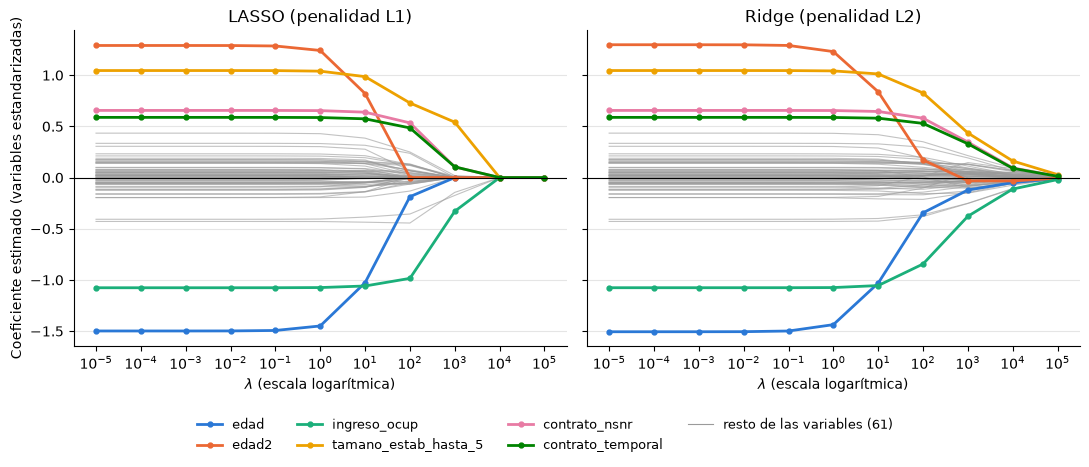

In [8]:
# Las seis variables a resaltar y sus colores (mismos tonos que las figuras del TP1)
destacadas = coefs["l1"][-5].abs().sort_values(ascending=False).index[:6].tolist()
paleta = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
color_var = dict(zip(destacadas, paleta))
print("Variables resaltadas:", destacadas)
print("\nCoeficientes de las resaltadas, LASSO:\n", coefs["l1"].loc[destacadas].round(3).to_string())
print("\nCoeficientes de las resaltadas, Ridge:\n", coefs["l2"].loc[destacadas].round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
for ax, tipo, titulo in zip(axes, ["l1", "l2"], ["LASSO (penalidad L1)", "Ridge (penalidad L2)"]):
    for var in x_cols:
        if var not in destacadas:
            ax.plot(lambdas, coefs[tipo].loc[var], color="#9a9a9a", linewidth=0.8, alpha=0.6)
    for var in destacadas:
        ax.plot(lambdas, coefs[tipo].loc[var], color=color_var[var], linewidth=2, marker="o",
                markersize=3.5, label=var)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xscale("log")
    ax.set_xticks(lambdas)
    ax.set_xticklabels(etiquetas_lambda)
    ax.minorticks_off()
    ax.set_xlabel("$\\lambda$ (escala logarítmica)")
    ax.set_title(titulo)
    ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Coeficiente estimado (variables estandarizadas)")
axes[0].plot([], [], color="#9a9a9a", linewidth=0.8, label="resto de las variables (61)")
manijas, rotulos = axes[0].get_legend_handles_labels()
fig.legend(manijas, rotulos, loc="lower center", ncol=4, frameon=False, fontsize=9,
           bbox_to_anchor=(0.5, -0.02))
plt.tight_layout(rect=(0, 0.1, 1, 1))
plt.savefig("figuras/coeficientes_lasso_ridge.png", dpi=200, bbox_inches="tight")
plt.show()

### Inciso 2
#### 2.1 Validación cruzada con `LogisticRegressionCV` (5 folds)
`LogisticRegressionCV` divide la base de entrenamiento en 5 partes; para cada λ de la grilla estima el
modelo con 4 partes y mide la accuracy en la quinta (validación), rotando la parte que queda afuera. Así
obtenemos 5 medidas de accuracy por cada λ. Elige el λ con mayor accuracy promedio y, con ese λ, vuelve a
estimar con toda la base de entrenamiento (`refit=True`).

Decisiones:
- **Folds.** Usamos `KFold(n_splits=5, shuffle=True, random_state=444)`, la misma partición en folds del
  inciso 9 del TP1, y la misma para LASSO y Ridge, así las dos penalidades se comparan sobre las mismas
  observaciones de validación. En las tutoriales aparecen las dos formas: `KFold(..., shuffle=True,
  random_state=...)` en la Tutorial 6 y `cv=5` en la Tutorial 5. Con `cv=5`, `LogisticRegressionCV` arma
  folds estratificados y sin mezclar; esa alternativa se evalúa en 2.6.
- **Criterio.** `scoring="accuracy"`; el error de clasificación es $1 - \text{accuracy}$.
- **Solvers y `max_iter`.** Los del inciso 1: `saga` para LASSO y `newton-cholesky` para Ridge, con
  `max_iter = 10.000`.
- **Estandarización.** Se usa la matriz estandarizada con las medias y los desvíos de toda la base de
  entrenamiento, como pide la consigna; no se vuelve a estandarizar dentro de cada fold.

In [9]:
folds = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)

def kw_cv():
    # Argumentos extra según la versión: en las versiones nuevas pedimos el formato nuevo de atributos
    extra = {}
    if "use_legacy_attributes" in inspect.signature(LogisticRegressionCV).parameters:
        extra["use_legacy_attributes"] = False
    return extra

cv_modelos, cv_avisos = {}, {}
for tipo in ["l1", "l2"]:
    t0 = time.perf_counter()
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always", ConvergenceWarning)
        cv_modelos[tipo] = LogisticRegressionCV(
            Cs=Cs, cv=folds, scoring="accuracy", solver=SOLVER[tipo], max_iter=MAX_ITER,
            random_state=SEMILLA, refit=True, **kw_penalidad(tipo, cv=True), **kw_cv()
        ).fit(X_train_std, y_train)
    cv_avisos[tipo] = sum(issubclass(a.category, ConvergenceWarning) for a in avisos)
    max_it = int(np.max(np.asarray(cv_modelos[tipo].n_iter_)))
    print(f"{nombre_pen[tipo]:5s} | solver {SOLVER[tipo]:15s} | {time.perf_counter() - t0:5.1f} s | "
          f"máx. iteraciones {max_it} | avisos de no convergencia: {cv_avisos[tipo]}")
    assert max_it < MAX_ITER and cv_avisos[tipo] == 0, "No convergió"

LASSO | solver saga            |  19.5 s | máx. iteraciones 324 | avisos de no convergencia: 0
Ridge | solver newton-cholesky |   0.7 s | máx. iteraciones 5 | avisos de no convergencia: 0


#### 2.2 Error de validación por fold y λ seleccionado
De cada modelo sacamos la tabla de accuracy (5 folds × 11 valores de λ) y la pasamos a error
($1 - \text{accuracy}$). El atributo `scores_` cambia de forma según la versión de scikit-learn, así que
`errores_cv` lo lleva siempre a una tabla con los folds en las filas y los λ en las columnas, ordenadas
de $10^{-5}$ a $10^{5}$. Después calculamos el error medio y el desvío entre folds para cada λ, y
comprobamos que el λ que reporta `LogisticRegressionCV` (`C_`) sea el de menor error medio. Si dos λ
empatan en el error medio, lo informamos.

In [10]:
def errores_cv(modelo):
    # Tabla folds x λ con el error de clasificación de validación (1 - accuracy)
    s = modelo.scores_
    s = s[1] if isinstance(s, dict) else s            # versiones viejas: diccionario por clase
    s = np.asarray(s).reshape(folds.get_n_splits(), len(Cs))
    tabla = pd.DataFrame(1 - s, columns=np.round(-np.log10(modelo.Cs_)).astype(int),
                         index=pd.Index(range(1, 6), name="fold"))
    tabla.columns.name = "n (lambda = 10^n)"
    return tabla[sorted(tabla.columns)]

errores, error_medio, error_desvio, n_cv = {}, {}, {}, {}
for tipo in ["l1", "l2"]:
    errores[tipo] = errores_cv(cv_modelos[tipo])
    error_medio[tipo] = errores[tipo].mean()
    error_desvio[tipo] = errores[tipo].std(ddof=1)        # desvío muestral entre los 5 folds
    C_cv = float(np.ravel(cv_modelos[tipo].C_)[0])
    n_cv[tipo] = int(round(-np.log10(C_cv)))             # λcv = 10^n
    empatados = error_medio[tipo][np.isclose(error_medio[tipo], error_medio[tipo].min())].index.tolist()

    print(f"===== {nombre_pen[tipo]} =====")
    print("Error de validación por fold (filas) y n (columnas):")
    print(errores[tipo].round(4).to_string())
    print("Media: ", error_medio[tipo].round(5).to_dict())
    print("Desvío:", error_desvio[tipo].round(5).to_dict())
    print(f"λcv = 10^{n_cv[tipo]} (C = {C_cv:g}) | error medio = {error_medio[tipo][n_cv[tipo]]:.5f}")
    print("λ con el mínimo error medio (n):", empatados, "\n")
    assert n_cv[tipo] in empatados

===== LASSO =====
Error de validación por fold (filas) y n (columnas):
n (lambda = 10^n)      -5      -4      -3      -2      -1       0       1       2       3       4       5
fold                                                                                                     
1                  0.1697  0.1697  0.1697  0.1697  0.1697  0.1690  0.1686  0.1653  0.2390  0.4340  0.4340
2                  0.1683  0.1683  0.1683  0.1683  0.1683  0.1683  0.1657  0.1719  0.2555  0.4388  0.4388
3                  0.1621  0.1621  0.1621  0.1621  0.1621  0.1617  0.1624  0.1702  0.2563  0.4547  0.4547
4                  0.1547  0.1547  0.1547  0.1547  0.1547  0.1544  0.1540  0.1544  0.2340  0.4415  0.4415
5                  0.1566  0.1566  0.1566  0.1566  0.1566  0.1569  0.1558  0.1573  0.2332  0.4675  0.4675
Media:  {-5: 0.16228, -4: 0.16228, -3: 0.16228, -2: 0.16228, -1: 0.16228, 0: 0.16206, 1: 0.16132, 2: 0.16382, 3: 0.2436, 4: 0.44731, 5: 0.44731}
Desvío: {-5: 0.00671, -4: 0.00671, -3: 0.0

#### 2.3 Tablas: λ seleccionado y error por λ
Dos tablas para el informe:
- `tablas/lambda_cv.tex`: para cada penalidad, el λ seleccionado, su error medio de validación, el desvío
  entre folds y la cantidad de coeficientes iguales a cero (sobre 67) en el modelo reestimado con toda la
  base de entrenamiento y ese λ.
- `tablas/error_cv_por_lambda.tex`: error medio y desvío entre folds para cada λ y cada penalidad.

La celda también comprueba que los coeficientes del modelo reestimado por `LogisticRegressionCV`
coincidan con los del inciso 1 para ese mismo λ.

In [11]:
filas = []
for tipo in ["l1", "l2"]:
    b = cv_modelos[tipo].coef_.ravel()
    dif = float(np.abs(b - coefs[tipo][n_cv[tipo]].values).max())
    filas.append({"penalidad": nombre_pen[tipo], "n": n_cv[tipo], "lambda_cv": 10.0 ** n_cv[tipo],
                  "error_medio": error_medio[tipo][n_cv[tipo]], "desvio": error_desvio[tipo][n_cv[tipo]],
                  "coef_cero": int(es_cero(b).sum()), "coef_no_cero": int((~es_cero(b)).sum()),
                  "dif_max_vs_inciso1": dif})
tabla_cv = pd.DataFrame(filas).set_index("penalidad")
print(tabla_cv.round(5).to_string())

for tipo in ["l1", "l2"]:
    b = pd.Series(cv_modelos[tipo].coef_.ravel(), index=x_cols)
    print(f"\n{nombre_pen[tipo]}: variables con coeficiente cero en λcv:", b[es_cero(b)].index.tolist())

# Tabla 1: λ seleccionado
lineas = [r"\begin{tabular}{lcrrr}", r"\toprule",
          r"Penalidad & $\lambda_{cv}$ & Error medio de validación & Desvío entre folds & "
          r"Coeficientes en cero (de 67) \\", r"\midrule"]
for pen, f in tabla_cv.iterrows():
    lineas.append(f"{pen} & $10^{{{int(f['n'])}}}$ & {formato(f['error_medio'], 4)} & "
                  f"{formato(f['desvio'], 4)} & {int(f['coef_cero'])} \\\\")
lineas += [r"\bottomrule", r"\end{tabular}"]
with open("tablas/lambda_cv.tex", "w", encoding="utf-8") as f:
    f.write("\n".join(lineas))

# Tabla 2: error por λ
lineas = [r"\begin{tabular}{crrrr}", r"\toprule",
          r" & \multicolumn{2}{c}{LASSO} & \multicolumn{2}{c}{Ridge} \\",
          r"\cmidrule(lr){2-3}\cmidrule(lr){4-5}",
          r"$\lambda$ & Error medio & Desvío & Error medio & Desvío \\", r"\midrule"]
for n in exponentes:
    lineas.append(f"$10^{{{n}}}$ & {formato(error_medio['l1'][n], 4)} & {formato(error_desvio['l1'][n], 4)} & "
                  f"{formato(error_medio['l2'][n], 4)} & {formato(error_desvio['l2'][n], 4)} \\\\")
lineas += [r"\bottomrule", r"\end{tabular}"]
with open("tablas/error_cv_por_lambda.tex", "w", encoding="utf-8") as f:
    f.write("\n".join(lineas))
print("\nGuardadas en tablas/lambda_cv.tex y tablas/error_cv_por_lambda.tex")

           n  lambda_cv  error_medio   desvio  coef_cero  coef_no_cero  dif_max_vs_inciso1
penalidad                                                                                 
LASSO      1       10.0      0.16132  0.00626          5            62             0.00005
Ridge      0        1.0      0.16206  0.00635          0            67             0.00005

LASSO: variables con coeficiente cero en λcv: ['menores10', 'sobrecalificacion', 'region_Pampeana', 'rama_industria', 'calificacion_no_calificada']

Ridge: variables con coeficiente cero en λcv: []

Guardadas en tablas/lambda_cv.tex y tablas/error_cv_por_lambda.tex


#### 2.4 Box-plots del error de validación
Un panel por penalidad. Cada caja corresponde a un valor de λ y resume los 5 errores de validación (uno
por fold); como son sólo 5 observaciones por caja, también dibujamos los 5 puntos. La caja del λ
seleccionado va en color y las demás en gris. Los dos paneles comparten el eje vertical. Se guarda en
`figuras/boxplot_error_cv.png`.

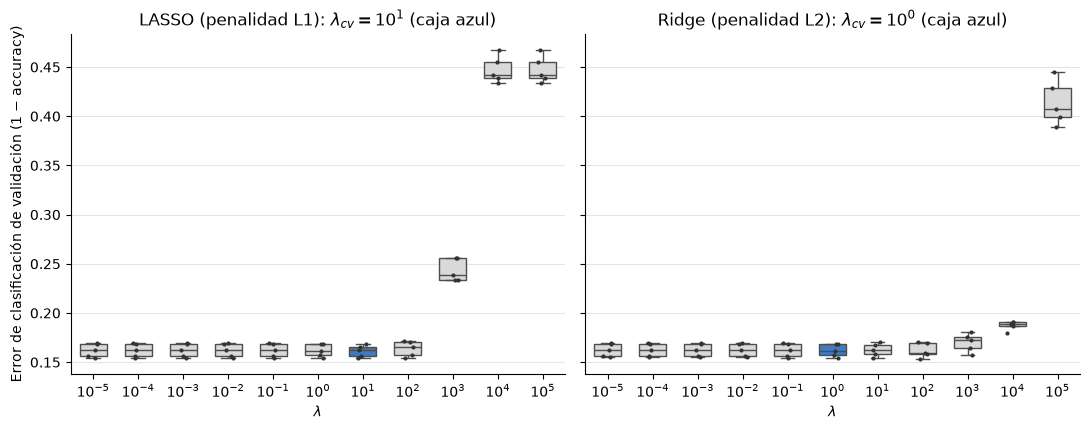

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for ax, tipo, titulo in zip(axes, ["l1", "l2"], ["LASSO (penalidad L1)", "Ridge (penalidad L2)"]):
    largo = errores[tipo].melt(var_name="n", value_name="error")     # una fila por (fold, λ)
    colores = ["#2a78d6" if n == n_cv[tipo] else "#d9d9d9" for n in exponentes]
    sns.boxplot(data=largo, x="n", y="error", order=list(exponentes), hue="n", hue_order=list(exponentes),
                palette=colores, legend=False, width=0.6, linewidth=1, fliersize=0, ax=ax)
    np.random.seed(SEMILLA)        # el desplazamiento horizontal de los puntos es aleatorio: lo fijamos
    sns.stripplot(data=largo, x="n", y="error", order=list(exponentes), color="#333333", size=3,
                  jitter=0.12, ax=ax)
    ax.set_xticks(range(len(exponentes)))
    ax.set_xticklabels(etiquetas_lambda)
    ax.set_xlabel("$\\lambda$")
    ax.set_ylabel("")
    ax.set_title(f"{titulo}: $\\lambda_{{cv}} = 10^{{{n_cv[tipo]}}}$ (caja azul)")
    ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Error de clasificación de validación (1 − accuracy)")
plt.tight_layout()
plt.savefig("figuras/boxplot_error_cv.png", dpi=200, bbox_inches="tight")
plt.show()

#### 2.5 Opcional: proporción de variables ignoradas por LASSO en función de λ
Para cada λ contamos cuántos de los 67 coeficientes de LASSO son cero (con `es_cero`, el criterio de la
Tutorial 5) y dividimos por 67, porque la consigna pide la proporción y no la cantidad.
Usamos los modelos del inciso 1, estimados con toda la base de entrenamiento (no los de cada fold).
La línea vertical punteada marca el λ seleccionado en 2.2. Se guarda en `figuras/lasso_proporcion_ceros.png`.

n (lambda = 10^n)   -5   -4   -3   -2   -1      0       1        2        3     4     5 
coef_en_cero       0.0  0.0  0.0  0.0  0.0  2.0000  5.0000  28.0000  59.0000  67.0  67.0
proporcion         0.0  0.0  0.0  0.0  0.0  0.0299  0.0746   0.4179   0.8806   1.0   1.0


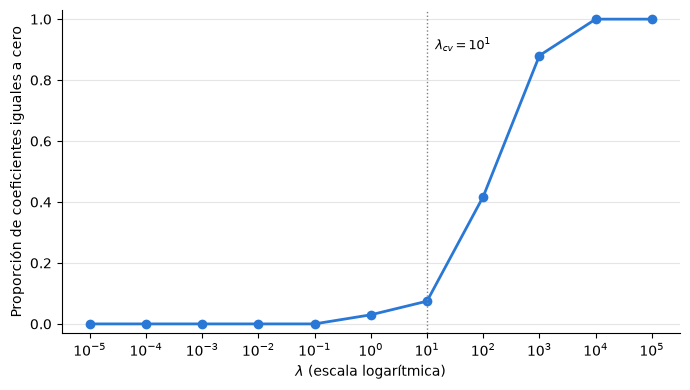

In [13]:
ceros = pd.Series(es_cero(coefs["l1"]).sum(axis=0), index=coefs["l1"].columns)
prop_ceros = ceros / len(x_cols)
print(pd.DataFrame({"coef_en_cero": ceros, "proporcion": prop_ceros.round(4)}).T.to_string())

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(lambdas, prop_ceros.values, color="#2a78d6", linewidth=2, marker="o", markersize=6)
ax.axvline(10.0 ** n_cv["l1"], color="gray", linestyle=":", linewidth=1)
ax.annotate(f"$\\lambda_{{cv}} = 10^{{{n_cv['l1']}}}$", xy=(10.0 ** n_cv["l1"], 0.9), xytext=(6, 0),
            textcoords="offset points", fontsize=9)
ax.set_xscale("log")
ax.set_xticks(lambdas)
ax.set_xticklabels(etiquetas_lambda)
ax.minorticks_off()
ax.set_ylim(-0.03, 1.03)
ax.set_xlabel("$\\lambda$ (escala logarítmica)")
ax.set_ylabel("Proporción de coeficientes iguales a cero")
ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("figuras/lasso_proporcion_ceros.png", dpi=200, bbox_inches="tight")
plt.show()

#### 2.6 Chequeo adicional (no lo pide la consigna): sensibilidad de $\lambda_{cv}$ a los folds
En 2.2 el error medio casi no cambia entre $\lambda = 10^{-5}$ y $\lambda = 10^{2}$: las diferencias son
de menos de 0,003, más chicas que el desvío entre folds. Cuando las diferencias son tan chicas, cuál
λ queda primero puede depender de qué observaciones cayeron en cada fold. Para medirlo repetimos la
validación cruzada con la partición por defecto de `LogisticRegressionCV` (`cv=5`: folds estratificados
y sin mezclar) y comparamos el λ elegido y los errores medios. Los resultados que van al informe son
los de 2.2; esta celda sólo sirve para saber cuánto dependen de los folds.

In [14]:
filas = {}
for tipo in ["l1", "l2"]:
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always", ConvergenceWarning)
        alt = LogisticRegressionCV(
            Cs=Cs, cv=5, scoring="accuracy", solver=SOLVER[tipo], max_iter=MAX_ITER,
            random_state=SEMILLA, refit=True, **kw_penalidad(tipo, cv=True), **kw_cv()
        ).fit(X_train_std, y_train)
    assert not any(issubclass(a.category, ConvergenceWarning) for a in avisos)
    n_alt = int(round(-np.log10(float(np.ravel(alt.C_)[0]))))
    medio_alt = errores_cv(alt).mean()
    filas[f"{nombre_pen[tipo]} | folds de 2.2 (KFold mezclado, semilla 444)"] = error_medio[tipo]
    filas[f"{nombre_pen[tipo]} | folds por defecto (cv=5)"] = medio_alt
    print(f"{nombre_pen[tipo]}: λcv con los folds de 2.2 = 10^{n_cv[tipo]} | "
          f"λcv con cv=5 por defecto = 10^{n_alt}")
print("\nError medio de validación por n (lambda = 10^n):")
print(pd.DataFrame(filas).T.round(5).to_string())

LASSO: λcv con los folds de 2.2 = 10^1 | λcv con cv=5 por defecto = 10^1
Ridge: λcv con los folds de 2.2 = 10^0 | λcv con cv=5 por defecto = 10^2

Error medio de validación por n (lambda = 10^n):
n (lambda = 10^n)                                        -5       -4       -3       -2       -1        0        1        2        3        4        5
LASSO | folds de 2.2 (KFold mezclado, semilla 444)  0.16228  0.16228  0.16228  0.16228  0.16228  0.16206  0.16132  0.16382  0.24360  0.44731  0.44731
LASSO | folds por defecto (cv=5)                    0.16338  0.16338  0.16338  0.16338  0.16331  0.16294  0.16221  0.16507  0.24411  0.44731  0.44731
Ridge | folds de 2.2 (KFold mezclado, semilla 444)  0.16235  0.16235  0.16235  0.16235  0.16228  0.16206  0.16242  0.16228  0.17005  0.18750  0.41388
Ridge | folds por defecto (cv=5)                    0.16338  0.16338  0.16338  0.16338  0.16338  0.16323  0.16228  0.16206  0.16969  0.18699  0.41461


### Inciso 3
#### 3.1 Logit sin penalidad, con LASSO y con Ridge
Estimamos los tres modelos con la misma matriz `X_train_std` (estandarizada con las medias y desvíos del
entrenamiento, sin columna de unos; el intercepto lo estima scikit-learn sin penalizarlo):
- **Sin penalidad.** En scikit-learn 1.8 o posterior se pide con `C = np.inf` (λ = 0); en versiones
  anteriores, con `penalty=None`. La función `kw_sin_penalidad` elige según la versión, como
  `kw_penalidad` en 0.1. Usamos `newton-cholesky`, el mismo solver que Ridge.
- **LASSO y Ridge.** Con el λcv elegido en 2.2 (`C = 1/λcv`) y los mismos solvers del inciso 1.


In [15]:
def kw_sin_penalidad():
    # Sin penalidad: en scikit-learn >= 1.8 se pide con C = infinito; antes, con penalty=None
    return {"C": np.inf} if SK_NUEVO else {"penalty": None}

especificaciones = {
    "sin": ("Sin penalidad", "newton-cholesky", kw_sin_penalidad()),
    "l1":  ("LASSO", SOLVER["l1"], {"C": 1 / 10.0 ** n_cv["l1"], **kw_penalidad("l1")}),
    "l2":  ("Ridge", SOLVER["l2"], {"C": 1 / 10.0 ** n_cv["l2"], **kw_penalidad("l2")}),
}

modelos3 = {}
for clave, (nombre, solver, kw) in especificaciones.items():
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always", ConvergenceWarning)
        modelos3[clave] = LogisticRegression(solver=solver, max_iter=MAX_ITER, random_state=SEMILLA,
                                             **kw).fit(X_train_std, y_train)
    n_avisos = sum(issubclass(a.category, ConvergenceWarning) for a in avisos)
    max_it = int(modelos3[clave].n_iter_.max())
    print(f"{nombre:13s} | solver {solver:15s} | C = {kw.get('C', 'inf (versión vieja)')} | "
          f"iteraciones {max_it} | avisos de no convergencia: {n_avisos}")
    assert max_it < MAX_ITER and n_avisos == 0, "No convergió"

# Control: LASSO y Ridge coinciden con los modelos que LogisticRegressionCV reestimó en 2.1
for tipo in ["l1", "l2"]:
    dif = float(np.abs(modelos3[tipo].coef_ - cv_modelos[tipo].coef_).max())
    print(f"{nombre_pen[tipo]}: diferencia máxima con el modelo de 2.1 = {dif:.1e}")
    assert dif < 1e-3

Sin penalidad | solver newton-cholesky | C = inf | iteraciones 5 | avisos de no convergencia: 0
LASSO         | solver saga            | C = 0.1 | iteraciones 251 | avisos de no convergencia: 0
Ridge         | solver newton-cholesky | C = 1.0 | iteraciones 5 | avisos de no convergencia: 0
LASSO: diferencia máxima con el modelo de 2.1 = 5.0e-05
Ridge: diferencia máxima con el modelo de 2.1 = 5.2e-05


#### 3.2 Tabla de coeficientes
Una fila por variable y tres columnas: sin penalidad, LASSO y Ridge. Al pie, la suma de valores absolutos
de los coeficientes ($\sum_j|\hat\beta_j|$, sin el intercepto) y la cantidad de coeficientes iguales a
cero (función `es_cero`). Se exportan dos versiones:
- `tablas/coeficientes_inciso3.tex`: el intercepto y las 67 variables (`longtable`, para consulta).
- `tablas/coeficientes_inciso3_reducida.tex`: para el informe, las 12 variables con mayor coeficiente en
  valor absoluto sin penalidad y las que LASSO lleva a cero.

In [16]:
coef3 = pd.DataFrame({col: np.r_[modelos3[k].intercept_[0], modelos3[k].coef_.ravel()]
                      for col, k in [("sin_penalidad", "sin"), ("lasso", "l1"), ("ridge", "l2")]},
                     index=["intercepto"] + x_cols)
b3 = coef3.drop("intercepto")                     # sólo los 67 coeficientes de las variables
print(coef3.round(4).to_string())

def tabla_coef3_latex(filas, archivo, completa):
    # completa=True: longtable (puede ocupar más de una página). completa=False: tabular.
    encabezado = (r"Variable & Sin penalidad & LASSO ($\lambda_{cv} = 10^{" + str(n_cv["l1"]) + r"}$) & "
                  r"Ridge ($\lambda_{cv} = 10^{" + str(n_cv["l2"]) + r"}$) \\")
    if completa:
        lineas = [r"\begin{longtable}{lrrr}", r"\toprule", encabezado, r"\midrule", r"\endfirsthead",
                  r"\toprule", encabezado, r"\midrule", r"\endhead"]
    else:
        lineas = [r"\begin{tabular}{lrrr}", r"\toprule", encabezado, r"\midrule"]
    for var in filas:
        f = coef3.loc[var]
        nombre = r"\texttt{" + var.replace("_", r"\_") + "}"
        lineas.append(f"{nombre} & {formato(f['sin_penalidad'], 4)} & {formato(f['lasso'], 4)} & "
                      f"{formato(f['ridge'], 4)} \\\\")
    lineas += [r"\midrule",
               r"$\sum_j |\hat\beta_j|$ & " + " & ".join(formato(v, 3) for v in b3.abs().sum()) + r" \\",
               r"Coeficientes en cero (de 67) & " +
               " & ".join(str(int(es_cero(b3[c]).sum())) for c in b3.columns) + r" \\",
               r"\bottomrule", r"\end{longtable}" if completa else r"\end{tabular}"]
    with open(archivo, "w", encoding="utf-8") as f:
        f.write("\n".join(lineas))

# Tabla completa: intercepto y las 67 variables, en el orden de la base
tabla_coef3_latex(["intercepto"] + x_cols, "tablas/coeficientes_inciso3.tex", completa=True)

# Tabla reducida: las 12 con mayor |coeficiente| sin penalidad y las que LASSO lleva a cero
mayores = b3["sin_penalidad"].abs().sort_values(ascending=False).index[:12].tolist()
ceros_lasso = b3.index[es_cero(b3["lasso"])].tolist()
tabla_coef3_latex(mayores + ceros_lasso, "tablas/coeficientes_inciso3_reducida.tex", completa=False)
print("\nReducida:", len(mayores), "con mayor |coeficiente| +", len(ceros_lasso),
      "en cero en LASSO:", ceros_lasso)
print("Guardadas en tablas/coeficientes_inciso3.tex y tablas/coeficientes_inciso3_reducida.tex")

                                 sin_penalidad   lasso   ridge
intercepto                             -0.5176 -0.5104 -0.5170
mas500                                  0.1757  0.1622  0.1753
jefe                                   -0.0605 -0.0671 -0.0620
mujer                                   0.0442  0.0191  0.0428
edad                                   -1.5060 -1.0266 -1.4366
asiste_educ                             0.0293  0.0340  0.0310
pluriempleo                             0.0715  0.0575  0.0709
quiere_mas_horas                        0.1439  0.1366  0.1435
busca_otro_empleo                       0.1563  0.1517  0.1561
contrato_temporal                       0.5879  0.5738  0.5870
ingreso_ocup                           -1.0759 -1.0591 -1.0745
ipcf                                    0.0777  0.0532  0.0772
menores10                              -0.0017  0.0000 -0.0009
edad2                                   1.2974  0.8204  1.2303
educ                                   -0.4075 -0.3860 

#### 3.3 Resumen numérico para la interpretación
Para cada penalidad, respecto del logit sin penalidad: la suma de valores absolutos, los coeficientes en
cero, la mediana de la razón $|\hat\beta_j^{pen}| / |\hat\beta_j^{sin}|$ (menor que 1 = el coeficiente se
achica), cuántos coeficientes crecen en valor absoluto y cuántos cambian de signo. También medimos cuánto
cambian las probabilidades predichas en la base de entrenamiento (la de test no se usa todavía).

In [17]:
resumen3 = pd.DataFrame({"suma_abs": b3.abs().sum(),
                         "coef_cero": [int(es_cero(b3[c]).sum()) for c in b3.columns]})
for col in ["lasso", "ridge"]:
    razon = b3[col].abs() / b3["sin_penalidad"].abs()          # |β penalizado| / |β sin penalidad|
    resumen3.loc[col, "razon_mediana"] = razon.median()
    resumen3.loc[col, "crecen"] = int((razon > 1).sum())
    resumen3.loc[col, "cambian_signo"] = int(((np.sign(b3[col]) != np.sign(b3["sin_penalidad"]))
                                              & ~es_cero(b3[col])).sum())
print(resumen3.round(4).to_string())

for col in ["lasso", "ridge"]:
    razon = b3[col].abs() / b3["sin_penalidad"].abs()
    print(f"\n{col}: variables cuyo |coeficiente| crece respecto de sin penalidad:",
          razon[razon > 1].round(3).sort_values(ascending=False).to_dict())

# Cuánto cambian las predicciones en entrenamiento
p3 = {k: m.predict_proba(X_train_std)[:, 1] for k, m in modelos3.items()}
for k in ["l1", "l2"]:
    dif = np.abs(p3[k] - p3["sin"])
    print(f"\n{nombre_pen[k]} vs. sin penalidad (entrenamiento): |Δp̂| medio = {dif.mean():.4f}, "
          f"máximo = {dif.max():.4f}; misma clasificación (umbral 0,5) en "
          f"{((p3[k] > 0.5) == (p3['sin'] > 0.5)).mean():.2%} de los casos")

               suma_abs  coef_cero  razon_mediana  crecen  cambian_signo
sin_penalidad   12.6922          0            NaN     NaN            NaN
lasso           10.8980          5         0.8953    12.0            0.0
ridge           12.5382          0         0.9976    20.0            0.0

lasso: variables cuyo |coeficiente| crece respecto de sin penalidad: {'estado_civil_viudo': 1.448, 'nhogar': 1.389, 'region_Patagonia': 1.353, 'calificacion_tecnica': 1.197, 'asiste_educ': 1.162, 'jefe': 1.107, 'rama_hoteles_restaurantes': 1.083, 'rama_construccion': 1.075, 'rama_otros_servicios': 1.063, 'rama_transporte_comunic': 1.062, 'sector_estatal': 1.017, 'estado_civil_unido': 1.015}

ridge: variables cuyo |coeficiente| crece respecto de sin penalidad: {'calificacion_no_calificada': 4.249, 'estado_civil_separado': 1.078, 'estado_civil_viudo': 1.074, 'rama_industria': 1.062, 'asiste_educ': 1.058, 'nhogar': 1.039, 'estado_civil_unido': 1.025, 'jefe': 1.024, 'region_Patagonia': 1.022, 'horastra

## Parte II: Árboles

### Inciso 4
#### 4.1 Árbol sin podar y grilla de `ccp_alpha`
Usamos `X_train` **sin estandarizar**. Así,
los cortes del árbol se leen en unidades reales (años, pesos, 0/1).

Primero estimamos el árbol sin podar (`ccp_alpha = 0`) con toda la base de entrenamiento.
`cost_complexity_pruning_path()` devuelve la secuencia de valores de α en los que el árbol pierde una rama,
desde el árbol completo hasta una sola hoja. Como la secuencia tiene cientos de valores, tomamos un
subconjunto: 30 puntos equiespaciados en escala logarítmica entre el menor y el mayor α de la secuencia
y, para cada uno, el α de la secuencia más cercano (sin repetidos).

In [18]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

arbol_completo = DecisionTreeClassifier(random_state=SEMILLA).fit(X_train, y_train)
print(f"Árbol sin podar: {arbol_completo.get_n_leaves()} hojas, profundidad {arbol_completo.get_depth()}, "
      f"accuracy en entrenamiento {arbol_completo.score(X_train, y_train):.4f}")

camino = arbol_completo.cost_complexity_pruning_path(X_train, y_train)
alphas_camino = camino.ccp_alphas[camino.ccp_alphas > 0]       # α = 0 es el árbol sin podar
print(f"Secuencia de poda: {len(alphas_camino)} valores de α, entre {alphas_camino.min():.2e} "
      f"y {alphas_camino.max():.4f}")

# Subconjunto: 30 puntos equiespaciados en escala logarítmica entre el menor y el mayor α de la
# secuencia; para cada uno tomamos el α de la secuencia más cercano (sin repetidos)
objetivos = np.geomspace(alphas_camino.min(), alphas_camino.max(), 30)
cercanos = [np.argmin(np.abs(np.log(alphas_camino) - np.log(o))) for o in objetivos]
grilla_alpha = alphas_camino[np.unique(cercanos)]
print(f"Grilla: {len(grilla_alpha)} valores de α")

Árbol sin podar: 1942 hojas, profundidad 29, accuracy en entrenamiento 1.0000
Secuencia de poda: 865 valores de α, entre 3.65e-05 y 0.1155
Grilla: 24 valores de α


#### 4.2 Validación cruzada con 10 folds
Con `GridSearchCV`, para cada α de la grilla se estima el árbol con 9 de los 10 folds de la base de
entrenamiento y se mide la accuracy en el fold que queda afuera. El error de clasificación es
$1 - \text{accuracy}$, promediado entre los 10 folds. Se elige el α de menor error medio y, con ese
α, el árbol se reestima con toda la base de entrenamiento (`refit=True`): ese es el árbol podado.
La tabla incluye el desvío entre folds (muestral, como en 2.2) y la cantidad de hojas del árbol estimado
con toda la base de entrenamiento para cada α.

In [19]:
folds10 = KFold(n_splits=10, shuffle=True, random_state=SEMILLA)

t0 = time.perf_counter()
arbol_cv = GridSearchCV(DecisionTreeClassifier(random_state=SEMILLA), {"ccp_alpha": grilla_alpha},
                        cv=folds10, scoring="accuracy", refit=True).fit(X_train, y_train)
print(f"Validación cruzada: {time.perf_counter() - t0:.1f} s")

res_arbol = pd.DataFrame({
    "ccp_alpha": grilla_alpha,
    "error_medio": 1 - arbol_cv.cv_results_["mean_test_score"],
    "desvio": np.std([arbol_cv.cv_results_[f"split{k}_test_score"] for k in range(10)], axis=0, ddof=1),
    "hojas": [DecisionTreeClassifier(random_state=SEMILLA, ccp_alpha=a).fit(X_train, y_train).get_n_leaves()
              for a in grilla_alpha]})
print(res_arbol.to_string(index=False, formatters={"ccp_alpha": "{:.2e}".format,
                                                   "error_medio": "{:.4f}".format,
                                                   "desvio": "{:.4f}".format}))

alpha_cv = arbol_cv.best_params_["ccp_alpha"]
arbol_podado = arbol_cv.best_estimator_            # reestimado con toda la base de entrenamiento
print(f"\nccp_alpha elegido = {alpha_cv:.2e} | error medio de validación = {1 - arbol_cv.best_score_:.4f} | "
      f"árbol podado: {arbol_podado.get_n_leaves()} hojas, profundidad {arbol_podado.get_depth()}")

Validación cruzada: 19.6 s
ccp_alpha error_medio desvio  hojas
 3.65e-05      0.2256 0.0100   1934
 4.82e-05      0.2256 0.0100   1903
 6.37e-05      0.2242 0.0098   1832
 8.38e-05      0.2128 0.0081   1438
 1.11e-04      0.2077 0.0093   1031
 1.47e-04      0.1988 0.0083    514
 1.93e-04      0.1887 0.0105    289
 2.54e-04      0.1832 0.0139    128
 3.41e-04      0.1802 0.0129     72
 4.37e-04      0.1775 0.0133     48
 5.92e-04      0.1753 0.0120     35
 7.79e-04      0.1749 0.0117     29
 1.01e-03      0.1769 0.0111     24
 1.35e-03      0.1811 0.0109     17
 1.79e-03      0.1851 0.0128     12
 2.12e-03      0.1852 0.0128     11
 2.84e-03      0.1865 0.0102     10
 3.79e-03      0.1891 0.0084      9
 5.94e-03      0.1973 0.0104      7
 8.44e-03      0.2004 0.0094      6
 9.18e-03      0.2035 0.0096      4
 1.38e-02      0.2255 0.0233      3
 4.88e-02      0.2600 0.0128      2
 1.15e-01      0.3603 0.0946      1

ccp_alpha elegido = 7.79e-04 | error medio de validación = 0.1749 | árbo

#### 4.3 Gráfico: error de validación en función de `ccp_alpha`
Error medio de validación (10 folds) para cada α de la grilla, con el eje horizontal en escala
logarítmica. La línea punteada marca el α elegido. Se guarda en `figuras/arbol_error_cv.png`.

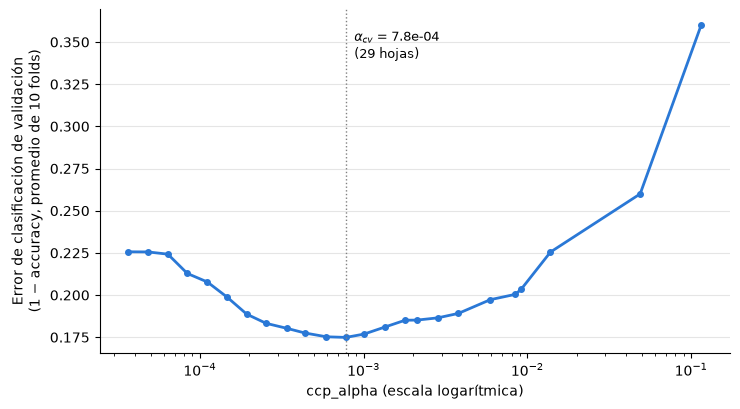

In [20]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(res_arbol["ccp_alpha"], res_arbol["error_medio"], color="#2a78d6", linewidth=2,
        marker="o", markersize=4)
ax.axvline(alpha_cv, color="gray", linestyle=":", linewidth=1)
ax.annotate(f"$\\alpha_{{cv}}$ = {alpha_cv:.1e}\n({arbol_podado.get_n_leaves()} hojas)",
            xy=(alpha_cv, res_arbol["error_medio"].max()), xytext=(6, -4), textcoords="offset points",
            fontsize=9, va="top")
ax.set_xscale("log")
ax.set_xlabel("ccp_alpha (escala logarítmica)")
ax.set_ylabel("Error de clasificación de validación\n(1 − accuracy, promedio de 10 folds)")
ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("figuras/arbol_error_cv.png", dpi=200, bbox_inches="tight")
plt.show()

### Inciso 5
#### 5.1 Panel A: árbol podado
Graficamos el árbol podado del inciso 4 (29 hojas). En cada nodo: la condición del corte (si se cumple,
se sigue por la izquierda), el porcentaje de la base de entrenamiento que llega a ese nodo (`samples`),
la proporción de formales e informales (`value`) y la clase mayoritaria (`class`), que es la
clasificación con umbral 0,5. El color indica la clase mayoritaria (naranja, formal; azul, informal) y
su intensidad, qué tan pura es la hoja. Los cortes están en unidades originales (ingresos en pesos, edad
y educación en años; las dummies cortan en 0,5). Se guarda en
`figuras/arbol_podado.png`.

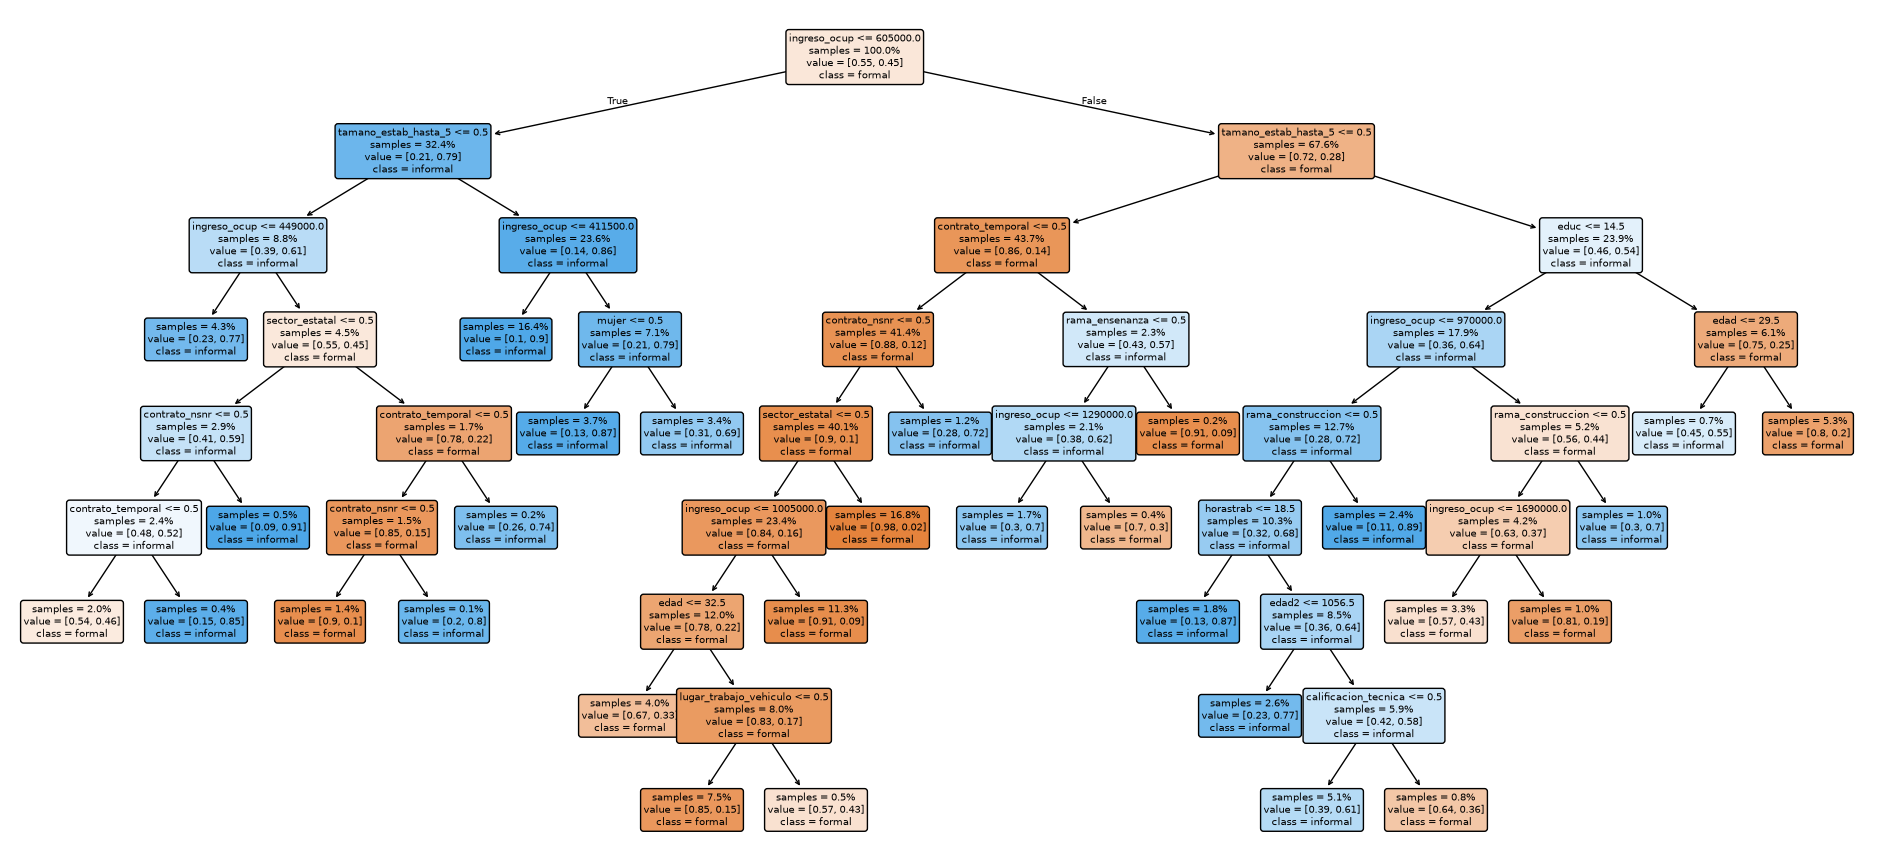

In [21]:
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(24, 11))
plot_tree(arbol_podado, feature_names=x_cols, class_names=["formal", "informal"], filled=True,
          rounded=True, impurity=False, proportion=True, precision=2, fontsize=7, ax=ax)
plt.savefig("figuras/arbol_podado.png", dpi=200, bbox_inches="tight")
plt.show()

#### 5.2 Panel B: importancia de los predictores
Usamos `feature_importances_`: para cada variable, suma la reducción de la impureza de Gini en los nodos que
cortan con ella, ponderada por la proporción de observaciones que llega a cada nodo, y divide por el
total de todos los nodos, de modo que las importancias suman 1. Se guarda en `figuras/arbol_importancia.png`.

Variables usadas en algún corte: 14 de 67; suma de importancias = 1.0000
ingreso_ocup              0.5352
tamano_estab_hasta_5      0.2333
educ                      0.0564
contrato_nsnr             0.0476
contrato_temporal         0.0453
sector_estatal            0.0270
rama_construccion         0.0143
edad                      0.0121
horastrab                 0.0063
edad2                     0.0056
rama_ensenanza            0.0050
mujer                     0.0049
calificacion_tecnica      0.0037
lugar_trabajo_vehiculo    0.0033


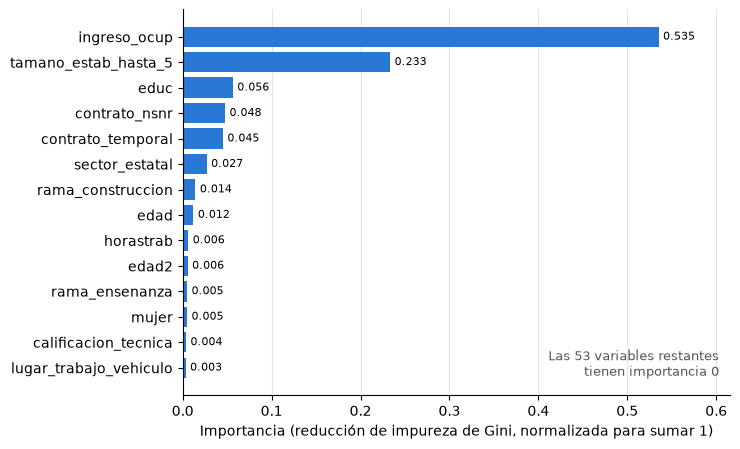

In [22]:
importancia = pd.Series(arbol_podado.feature_importances_, index=x_cols).sort_values(ascending=False)
usadas = importancia[importancia > 0]
print(f"Variables usadas en algún corte: {len(usadas)} de {len(x_cols)}; "
      f"suma de importancias = {importancia.sum():.4f}")
print(usadas.round(4).to_string())

fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.barh(usadas.index[::-1], usadas.values[::-1], color="#2a78d6")
for y, v in enumerate(usadas.values[::-1]):
    ax.text(v + 0.005, y, f"{v:.3f}", va="center", fontsize=8)
ax.set_xlabel("Importancia (reducción de impureza de Gini, normalizada para sumar 1)")
ax.set_xlim(0, usadas.max() * 1.15)
ax.text(0.98, 0.04, f"Las {len(x_cols) - len(usadas)} variables restantes\ntienen importancia 0",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=9, color="#555555")
ax.grid(axis="x", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("figuras/arbol_importancia.png", dpi=200, bbox_inches="tight")
plt.show()